In [1]:
# ==================================================
# CELL 1: Load Data + Train-Test Split
# ==================================================
# Tujuan: Memuat data bersih dan membagi menjadi data latih & data uji

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
from sklearn_genetic import GASearchCV
from sklearn_genetic.space import Integer
import joblib
import os
import warnings
warnings.filterwarnings("ignore")

print("Mengimpor data bersih...")

df_model = pd.read_csv('../data/processed/data_siap_model_skenario_b.csv')

# Pisahkan fitur (X) dan target (y)
X = df_model.drop(columns=['Log_Market_Value'])
y = df_model['Log_Market_Value']

# Split 80:20 dengan random_state agar hasil konsisten
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\n--- STATUS PEMBAGIAN DATA ---")
print(f"Data Latih (80%): {X_train.shape}")
print(f"Data Uji   (20%): {X_test.shape}")
print("Arena pemodelan siap!")

Mengimpor data bersih...

--- STATUS PEMBAGIAN DATA ---
Data Latih (80%): (1672, 19)
Data Uji   (20%): (418, 19)
Arena pemodelan siap!


In [2]:
# ==================================================
# CELL 2: Random Forest Default (Baseline)
# ==================================================
# Tujuan: Melatih model dengan parameter default sebagai baseline

print("Melatih Model Random Forest Default...")

rf_default = RandomForestRegressor(random_state=42)
rf_default.fit(X_train, y_train)

# Prediksi (masih dalam skala log)
y_pred_log = rf_default.predict(X_test)

# Inverse transform ke skala Euro
y_test_asli = np.expm1(y_test)
y_pred_asli = np.expm1(y_pred_log)

# Hitung metrik
r2_default = r2_score(y_test_asli, y_pred_asli)
rmse_default = np.sqrt(mean_squared_error(y_test_asli, y_pred_asli))

print("\n--- HASIL MODEL DEFAULT ---")
print(f"R²     : {r2_default:.4f}")
print(f"RMSE   : € {rmse_default:,.2f}")

Melatih Model Random Forest Default...

--- HASIL MODEL DEFAULT ---
R²     : 0.4583
RMSE   : € 13,797,607.78


In [3]:
# ==================================================
# CELL 3: Optimasi Hyperparameter dengan GASearchCV (Enhanced)
# ==================================================
# Tujuan: Mencari kombinasi hyperparameter terbaik
# Konfigurasi diperbesar: population=20, generations=10

print("Memulai evolusi Algoritma Genetika (Enhanced)...")
print("Konfigurasi: population_size=20 | generations=10")
print("Mohon tunggu, proses ini memakan waktu lebih lama...\n")

# Ruang pencarian (sedikit diperluas)
param_grid = {
    'n_estimators': Integer(50, 400),       # diperluas dari 300 → 400
    'max_depth': Integer(5, 40),            # diperluas dari 30 → 40
    'min_samples_split': Integer(2, 15),    # diperluas dari 10 → 15
    'min_samples_leaf': Integer(1, 10)
}

rf_base = RandomForestRegressor(random_state=42)

evolved_rf = GASearchCV(
    estimator=rf_base,
    cv=3,
    scoring='r2',
    population_size=20,          # dinaikkan dari 10
    generations=10,              # dinaikkan dari 5
    tournament_size=3,
    elitism=True,
    crossover_probability=0.8,
    mutation_probability=0.1,
    param_grid=param_grid,
    criteria='max',
    algorithm='eaMuPlusLambda',
    n_jobs=-1,
    verbose=True,
    keep_top_k=4,
    random_state=42
)

# Proses evolusi
evolved_rf.fit(X_train, y_train)

# Ambil model terbaik
best_model = evolved_rf.best_estimator_
y_pred_log_ga = best_model.predict(X_test)
y_pred_asli_ga = np.expm1(y_pred_log_ga)

# Hitung metrik
r2_ga = r2_score(y_test_asli, y_pred_asli_ga)
rmse_ga = np.sqrt(mean_squared_error(y_test_asli, y_pred_asli_ga))

print("\n--- HASIL MODEL GA OPTIMIZED (Enhanced) ---")
print(f"R²     : {r2_ga:.4f}")
print(f"RMSE   : € {rmse_ga:,.2f}")
print(f"\nParameter Terbaik:\n{evolved_rf.best_params_}")

Memulai evolusi Algoritma Genetika (Enhanced)...
Konfigurasi: population_size=20 | generations=10
Mohon tunggu, proses ini memakan waktu lebih lama...

 gen evals           avg          best     div  unique  stag     mut   sel             events
---- ----- ------------- ------------- ------- ------- ----- ------- ----- ------------------
   0    20       0.48137       0.48637   0.763   1.000     0       -     - -                 
   1    40       0.48414       0.48641   0.500   0.800     0   0.100     3 dup=7             
   2    40       0.48538       0.48641   0.408   0.650     1   0.100     3 dup=11            
   3    40       0.48615       0.48683   0.224   0.650     0   0.100     3 dup=14            
   4    40       0.48647       0.48687   0.145   0.700     0   0.200     3 div,imm=4,dup=15  
   5    40       0.48614       0.48727   0.289   0.900     0   0.200     3 div,imm=4,dup=19  
   6    40       0.48669       0.48727   0.184   0.650     1   0.100     3 dup=22            
  

In [4]:
# ==================================================
# CELL 4: Simpan Model Terbaik + Hasil Evaluasi
# ==================================================
# Tujuan: Mengunci hasil agar bisa dipakai ulang tanpa training ulang

os.makedirs('../models', exist_ok=True)

# Simpan model
joblib.dump(best_model, '../models/rf_ga_best_model.joblib')
joblib.dump(rf_default, '../models/rf_default_model.joblib')

# Simpan ringkasan hasil
hasil_evaluasi = {
    'best_params': evolved_rf.best_params_,
    'r2_default': float(r2_default),
    'rmse_default': float(rmse_default),
    'r2_ga': float(r2_ga),
    'rmse_ga': float(rmse_ga),
    'n_train': X_train.shape[0],
    'n_test': X_test.shape[0],
    'config': {
        'population_size': 20,
        'generations': 10
    }
}

joblib.dump(hasil_evaluasi, '../models/hasil_evaluasi.joblib')

print("Model dan hasil evaluasi berhasil disimpan ke folder '../models/'")
print("- rf_ga_best_model.joblib")
print("- rf_default_model.joblib")
print("- hasil_evaluasi.joblib")

Model dan hasil evaluasi berhasil disimpan ke folder '../models/'
- rf_ga_best_model.joblib
- rf_default_model.joblib
- hasil_evaluasi.joblib


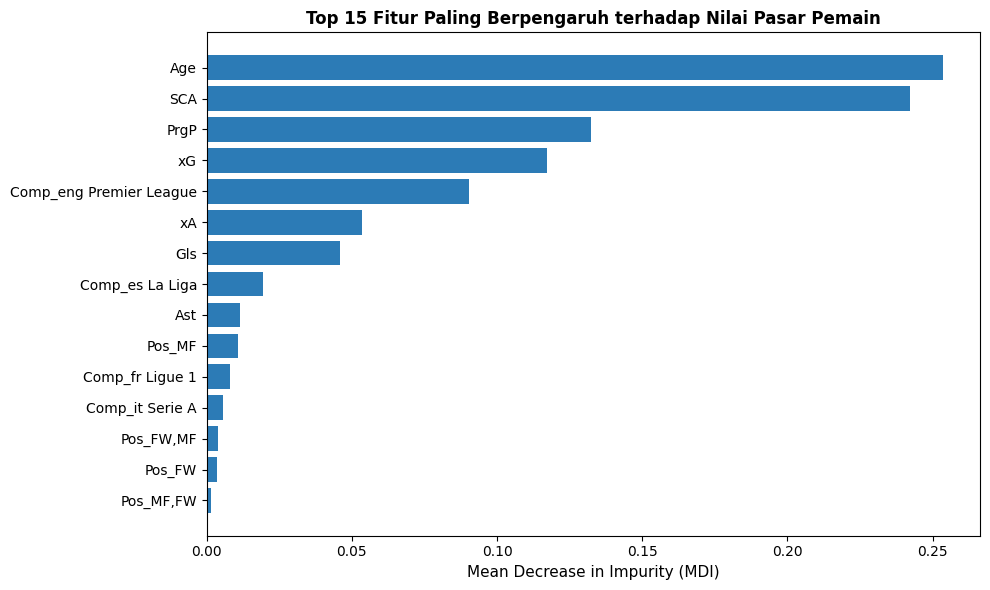


Top 15 Feature Importance:


,Feature,Importance
0,Age,0.253635
1,SCA,0.242071
2,PrgP,0.132416
3,xG,0.117164
4,Comp_eng Premier League,0.090317
5,xA,0.053500
6,Gls,0.045903
7,Comp_es La Liga,0.019408
8,Ast,0.011458
9,Pos_MF,0.010615


In [5]:
# ==================================================
# CELL 5: Feature Importance (Top 15)
# ==================================================
# Tujuan: Menampilkan 15 fitur paling berpengaruh terhadap prediksi nilai pasar

import pandas as pd
import matplotlib.pyplot as plt

# Ambil importance dari model terbaik
importances = best_model.feature_importances_
feature_names = X_train.columns

# Buat DataFrame dan urutkan
fi_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=False).head(15)

# Visualisasi
plt.figure(figsize=(10, 6))
plt.barh(fi_df['Feature'][::-1], fi_df['Importance'][::-1], color='#2c7bb6')
plt.xlabel('Mean Decrease in Impurity (MDI)', fontsize=11)
plt.title('Top 15 Fitur Paling Berpengaruh terhadap Nilai Pasar Pemain', 
          fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('../results/figures/feature_importance_top15.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nTop 15 Feature Importance:")
display(fi_df.reset_index(drop=True))

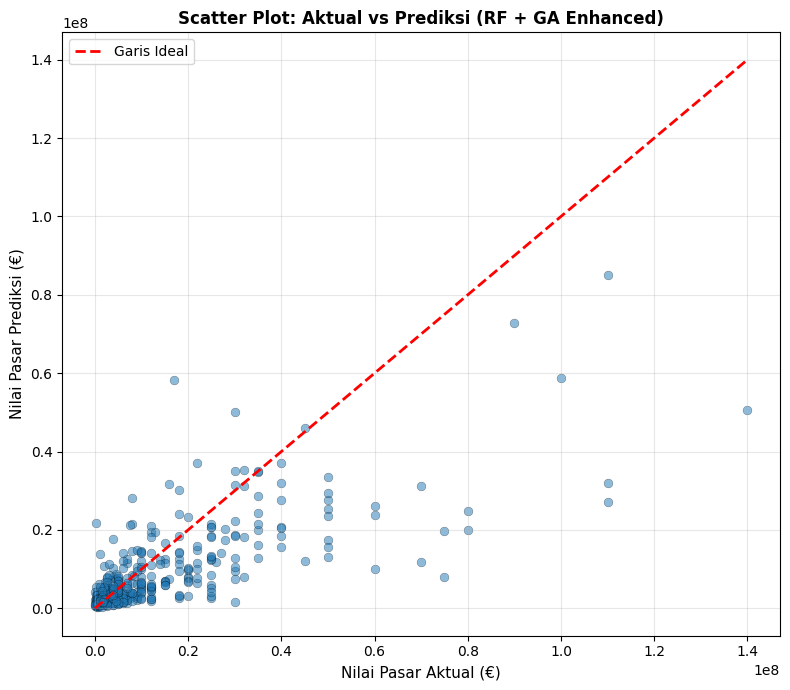

In [6]:
# ==================================================
# CELL 6: Scatter Plot Nilai Aktual vs Prediksi
# ==================================================
# Tujuan: Melihat seberapa dekat prediksi model dengan nilai sebenarnya

plt.figure(figsize=(8, 7))

plt.scatter(y_test_asli, y_pred_asli_ga, alpha=0.5, edgecolors='k', linewidth=0.3, s=40)
plt.plot([y_test_asli.min(), y_test_asli.max()],
         [y_test_asli.min(), y_test_asli.max()],
         'r--', lw=2, label='Garis Ideal')

plt.xlabel('Nilai Pasar Aktual (€)', fontsize=11)
plt.ylabel('Nilai Pasar Prediksi (€)', fontsize=11)
plt.title('Scatter Plot: Aktual vs Prediksi (RF + GA Enhanced)', 
          fontsize=12, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../results/figures/scatter_aktual_vs_prediksi.png', dpi=150, bbox_inches='tight')
plt.show()

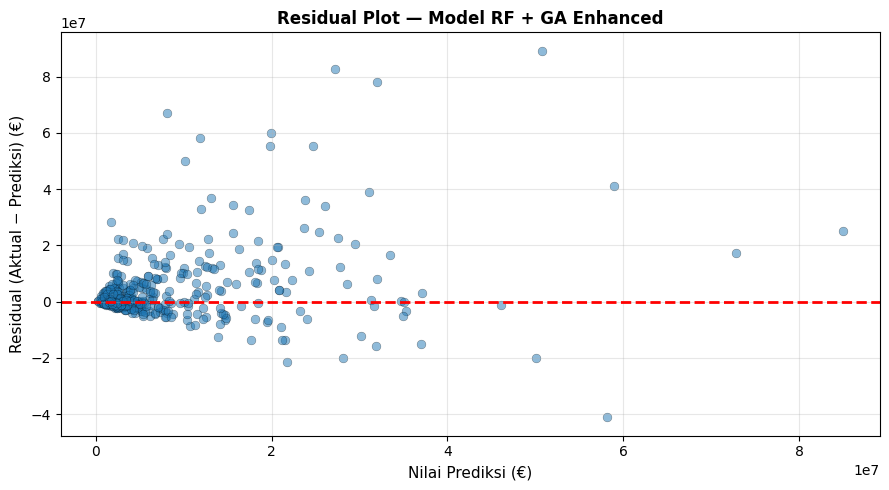

Rata-rata residual     : € 4,093,303
Std residual           : € 12,867,078
Underestimation > €60jt: 15 pemain


In [7]:
# ==================================================
# CELL 8: Residual Plot (Analisis Galat Prediksi)
# ==================================================
# Tujuan: Melihat pola residual dan underestimation pada pemain mahal

residuals = y_test_asli - y_pred_asli_ga

plt.figure(figsize=(9, 5))
plt.scatter(y_pred_asli_ga, residuals, alpha=0.5, edgecolors='k', linewidth=0.3, s=40)
plt.axhline(0, color='red', linestyle='--', lw=2)
plt.xlabel('Nilai Prediksi (€)', fontsize=11)
plt.ylabel('Residual (Aktual − Prediksi) (€)', fontsize=11)
plt.title('Residual Plot — Model RF + GA Enhanced', fontsize=12, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../results/figures/residual_plot.png', dpi=150, bbox_inches='tight')
plt.show()

# Ringkasan residual
print(f"Rata-rata residual     : € {residuals.mean():,.0f}")
print(f"Std residual           : € {residuals.std():,.0f}")
print(f"Underestimation > €60jt: {( (y_test_asli > 60_000_000) & (residuals > 0) ).sum()} pemain")

Menghitung RMSE 10-Fold Cross-Validation...


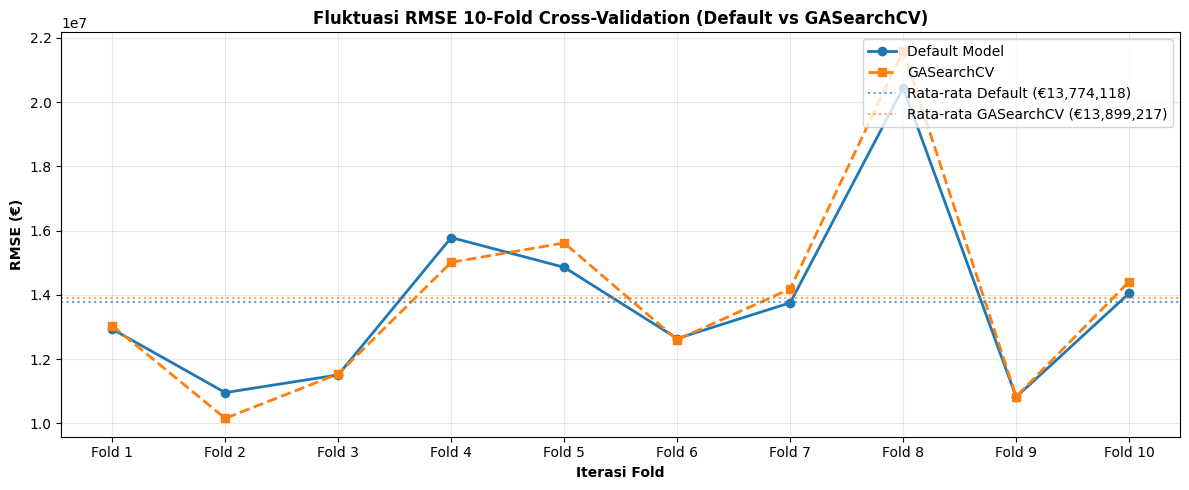


Rata-rata RMSE Default : € 13,774,117.90
Rata-rata RMSE GA      : € 13,899,216.56


In [8]:
# ==================================================
# CELL 10: Line Chart Fluktuasi RMSE 10-Fold CV
# ==================================================
# Tujuan: Membandingkan stabilitas model Default vs GA di setiap fold

from sklearn.model_selection import KFold
import numpy as np
import matplotlib.pyplot as plt

print("Menghitung RMSE 10-Fold Cross-Validation...")

kf = KFold(n_splits=10, shuffle=True, random_state=42)

rmse_default_folds = []
rmse_ga_folds = []

X_arr = X_train.values
y_arr = y_train.values

for train_idx, val_idx in kf.split(X_arr):
    X_tr, X_val = X_arr[train_idx], X_arr[val_idx]
    y_tr, y_val = y_arr[train_idx], y_arr[val_idx]

    # --- Model Default ---
    model_def = RandomForestRegressor(random_state=42)
    model_def.fit(X_tr, y_tr)
    pred_def = np.expm1(model_def.predict(X_val))
    actual = np.expm1(y_val)
    rmse_default_folds.append(np.sqrt(mean_squared_error(actual, pred_def)))

    # --- Model GA (pakai best_params) ---
    model_ga = RandomForestRegressor(**evolved_rf.best_params_, random_state=42)
    model_ga.fit(X_tr, y_tr)
    pred_ga = np.expm1(model_ga.predict(X_val))
    rmse_ga_folds.append(np.sqrt(mean_squared_error(actual, pred_ga)))

# --- Visualisasi ---
folds = [f'Fold {i}' for i in range(1, 11)]
mean_def = np.mean(rmse_default_folds)
mean_ga = np.mean(rmse_ga_folds)

plt.figure(figsize=(12, 5))
plt.plot(folds, rmse_default_folds, marker='o', linewidth=2, color='#1f77b4', label='Default Model')
plt.plot(folds, rmse_ga_folds, marker='s', linewidth=2, linestyle='--', color='#ff7f0e', label='GASearchCV')

plt.axhline(mean_def, color='#1f77b4', linestyle=':', alpha=0.7, label=f'Rata-rata Default (€{mean_def:,.0f})')
plt.axhline(mean_ga, color='#ff7f0e', linestyle=':', alpha=0.7, label=f'Rata-rata GASearchCV (€{mean_ga:,.0f})')

plt.title('Fluktuasi RMSE 10-Fold Cross-Validation (Default vs GASearchCV)', fontsize=12, fontweight='bold')
plt.xlabel('Iterasi Fold', fontsize=10, fontweight='bold')
plt.ylabel('RMSE (€)', fontsize=10, fontweight='bold')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../results/figures/rmse_10fold_linechart.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nRata-rata RMSE Default : € {mean_def:,.2f}")
print(f"Rata-rata RMSE GA      : € {mean_ga:,.2f}")

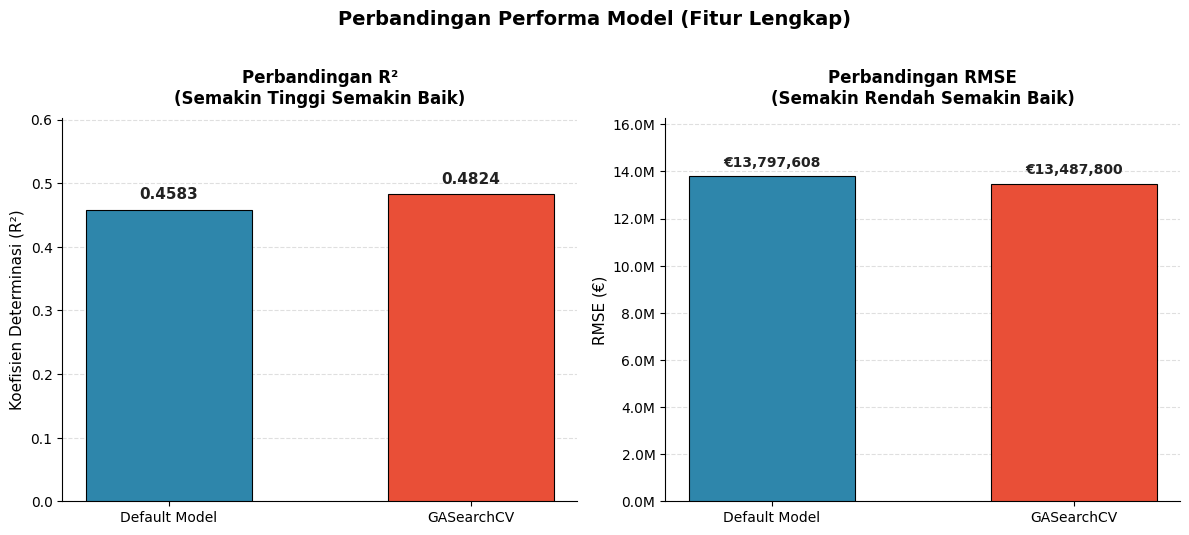

In [9]:
# ==================================================
# CELL 11: Diagram Batang Perbandingan R² & RMSE (Upgraded)
# ==================================================
# Tujuan: Visualisasi komparatif performa Default vs GA Optimized
#         dengan gaya yang lebih profesional dan mudah dibaca

import matplotlib.pyplot as plt
import numpy as np

# --- Data ---
models = ['Default Model', 'GASearchCV']
r2_values = [r2_default, r2_ga]
rmse_values = [rmse_default, rmse_ga]

# Warna profesional
color_default = '#2E86AB'   # biru tua
color_ga = '#E94F37'        # oranye-merah
colors = [color_default, color_ga]

# --- Setup figure ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
fig.patch.set_facecolor('white')

# ==================================================
# SUBPLOT 1: R²
# ==================================================
bars1 = axes[0].bar(
    models, r2_values,
    color=colors,
    edgecolor='black',
    linewidth=0.8,
    width=0.55,
    zorder=3
)

axes[0].set_ylabel('Koefisien Determinasi (R²)', fontsize=11, fontweight='medium')
axes[0].set_title('Perbandingan R²\n(Semakin Tinggi Semakin Baik)', 
                  fontsize=12, fontweight='bold', pad=10)
axes[0].set_ylim(0, max(r2_values) * 1.25)
axes[0].axhline(0, color='gray', linewidth=0.7, zorder=1)
axes[0].yaxis.grid(True, linestyle='--', alpha=0.4, zorder=0)
axes[0].set_axisbelow(True)

# Hapus spine atas & kanan
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# Label nilai di atas batang
for bar, val in zip(bars1, r2_values):
    axes[0].text(
        bar.get_x() + bar.get_width()/2,
        val + 0.012,
        f'{val:.4f}',
        ha='center', va='bottom',
        fontsize=11, fontweight='bold',
        color='#222222'
    )

# ==================================================
# SUBPLOT 2: RMSE
# ==================================================
bars2 = axes[1].bar(
    models, rmse_values,
    color=colors,
    edgecolor='black',
    linewidth=0.8,
    width=0.55,
    zorder=3
)

axes[1].set_ylabel('RMSE (€)', fontsize=11, fontweight='medium')
axes[1].set_title('Perbandingan RMSE\n(Semakin Rendah Semakin Baik)', 
                  fontsize=12, fontweight='bold', pad=10)
axes[1].set_ylim(0, max(rmse_values) * 1.18)
axes[1].yaxis.grid(True, linestyle='--', alpha=0.4, zorder=0)
axes[1].set_axisbelow(True)

axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

# Format sumbu Y agar lebih rapi (dalam juta)
axes[1].yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M')
)

# Label nilai di atas batang
for bar, val in zip(bars2, rmse_values):
    axes[1].text(
        bar.get_x() + bar.get_width()/2,
        val + max(rmse_values)*0.02,
        f'€{val:,.0f}',
        ha='center', va='bottom',
        fontsize=10, fontweight='bold',
        color='#222222'
    )

# ==================================================
# Judul utama & layout
# ==================================================
fig.suptitle(
    'Perbandingan Performa Model (Fitur Lengkap)',
    fontsize=14, fontweight='bold', y=1.02
)

plt.tight_layout()
plt.savefig('../results/figures/bar_r2_rmse_comparison.png', 
            dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

In [10]:
# ==================================================
# CELL 10: Paired T-test (Validasi Signifikansi GA)
# ==================================================
# Tujuan: Menguji apakah perbedaan RMSE antara Model Default
#         dan Model GA signifikan secara statistik

from sklearn.model_selection import KFold
from scipy import stats
import numpy as np

print("Menghitung RMSE per fold untuk Paired T-test...")
print("Mohon tunggu sebentar...\n")

kf = KFold(n_splits=10, shuffle=True, random_state=42)

rmse_default_folds = []
rmse_ga_folds = []

X_arr = X_train.values
y_arr = y_train.values

for fold, (train_idx, val_idx) in enumerate(kf.split(X_arr), 1):
    X_tr, X_val = X_arr[train_idx], X_arr[val_idx]
    y_tr, y_val = y_arr[train_idx], y_arr[val_idx]

    # --- Model Default ---
    model_def = RandomForestRegressor(random_state=42)
    model_def.fit(X_tr, y_tr)
    pred_def = np.expm1(model_def.predict(X_val))
    actual = np.expm1(y_val)
    rmse_def = np.sqrt(mean_squared_error(actual, pred_def))
    rmse_default_folds.append(rmse_def)

    # --- Model GA (menggunakan best_params) ---
    model_ga = RandomForestRegressor(**evolved_rf.best_params_, random_state=42)
    model_ga.fit(X_tr, y_tr)
    pred_ga = np.expm1(model_ga.predict(X_val))
    rmse_ga_fold = np.sqrt(mean_squared_error(actual, pred_ga))
    rmse_ga_folds.append(rmse_ga_fold)

    print(f"Fold {fold:2d} | Default: €{rmse_def:>12,.0f} | GA: €{rmse_ga_fold:>12,.0f}")

# --- Paired T-test ---
t_stat, p_value = stats.ttest_rel(rmse_default_folds, rmse_ga_folds)

print("\n" + "=" * 55)
print("           HASIL PAIRED T-TEST")
print("=" * 55)
print(f"Rata-rata RMSE Default : € {np.mean(rmse_default_folds):,.2f}")
print(f"Rata-rata RMSE GA      : € {np.mean(rmse_ga_folds):,.2f}")
print(f"T-statistic            : {t_stat:.4f}")
print(f"P-value                : {p_value:.4f}")

alpha = 0.05
if p_value < alpha:
    print(f"\nKesimpulan: p-value < {alpha}")
    print("→ Perbedaan RMSE SIGNIFIKAN secara statistik.")
    print("→ Model GA terbukti lebih baik secara signifikan.")
else:
    print(f"\nKesimpulan: p-value ≥ {alpha}")
    print("→ Perbedaan RMSE TIDAK signifikan secara statistik.")
    print("→ Peningkatan GA masih bersifat marginal.")
print("=" * 55)

Menghitung RMSE per fold untuk Paired T-test...
Mohon tunggu sebentar...

Fold  1 | Default: €  12,932,580 | GA: €  13,039,782
Fold  2 | Default: €  10,956,267 | GA: €  10,155,053
Fold  3 | Default: €  11,507,991 | GA: €  11,538,048
Fold  4 | Default: €  15,783,423 | GA: €  15,012,893
Fold  5 | Default: €  14,856,799 | GA: €  15,614,368
Fold  6 | Default: €  12,639,218 | GA: €  12,602,078
Fold  7 | Default: €  13,752,860 | GA: €  14,186,587
Fold  8 | Default: €  20,444,829 | GA: €  21,599,628
Fold  9 | Default: €  10,818,530 | GA: €  10,831,592
Fold 10 | Default: €  14,048,685 | GA: €  14,412,137

           HASIL PAIRED T-TEST
Rata-rata RMSE Default : € 13,774,117.90
Rata-rata RMSE GA      : € 13,899,216.56
T-statistic            : -0.6513
P-value                : 0.5312

Kesimpulan: p-value ≥ 0.05
→ Perbedaan RMSE TIDAK signifikan secara statistik.
→ Peningkatan GA masih bersifat marginal.


In [11]:
# ==================================================
# CELL 5: Ringkasan Hasil Akhir (Siap untuk Laporan)
# ==================================================
# Tujuan: Menampilkan ringkasan bersih yang siap disalin ke laporan

print("=" * 60)
print("       RINGKASAN HASIL AKHIR — ta-estimasi-v2")
print("=" * 60)

print("\n[1] INFORMASI DATA")
print(f"  Total data bersih     : {X_train.shape[0] + X_test.shape[0]}")
print(f"  Data Latih (80%)      : {X_train.shape[0]}")
print(f"  Data Uji (20%)        : {X_test.shape[0]}")
print(f"  Jumlah fitur          : {X_train.shape[1]}")

print("\n[2] PERFORMA MODEL DEFAULT")
print(f"  R²                    : {r2_default:.4f}")
print(f"  RMSE                  : € {rmse_default:,.2f}")

print("\n[3] PERFORMA MODEL GA OPTIMIZED (Enhanced)")
print(f"  R²                    : {r2_ga:.4f}")
print(f"  RMSE                  : € {rmse_ga:,.2f}")

print("\n[4] HYPERPARAMETER TERBAIK")
for param, value in evolved_rf.best_params_.items():
    print(f"  {param:<22}: {value}")

print("\n[5] KONFIGURASI GA YANG DIGUNAKAN")
print("  population_size       : 20")
print("  generations           : 10")
print("  cv                    : 3")

print("\n" + "=" * 60)
print("  Selesai. Angka di atas siap disalin ke laporan.")
print("=" * 60)

       RINGKASAN HASIL AKHIR — ta-estimasi-v2

[1] INFORMASI DATA
  Total data bersih     : 2090
  Data Latih (80%)      : 1672
  Data Uji (20%)        : 418
  Jumlah fitur          : 19

[2] PERFORMA MODEL DEFAULT
  R²                    : 0.4583
  RMSE                  : € 13,797,607.78

[3] PERFORMA MODEL GA OPTIMIZED (Enhanced)
  R²                    : 0.4824
  RMSE                  : € 13,487,799.54

[4] HYPERPARAMETER TERBAIK
  n_estimators          : 102
  max_depth             : 28
  min_samples_split     : 15
  min_samples_leaf      : 5

[5] KONFIGURASI GA YANG DIGUNAKAN
  population_size       : 20
  generations           : 10
  cv                    : 3

  Selesai. Angka di atas siap disalin ke laporan.
